###Installing the required libraries

In [ ]:
!pip -q install -U transformers datasets accelerate evaluate soundfile librosa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 51.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.6/294.6 kB 26.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 12.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 25.0.1 which is incompatible.


###Loading IndicWav2vec (AI4 Bharath model)

In [ ]:
import os
import urllib.request
import torch

MODEL_DIR = "/content/indicwav2vec"
MODEL_PATH = os.path.join(MODEL_DIR, "indicw2v_base_pretrained.pt")

os.makedirs(MODEL_DIR, exist_ok=True)

MODEL_URL = (
    "https://objectstore.e2enetworks.net/"
    "indic-superb/aaai_ckpts/pretrained_models/"
    "indicw2v_base_pretrained.pt"
)

print("Downloading official IndicWav2Vec Base checkpoint...")
urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

size_mb = os.path.getsize(MODEL_PATH) / (1024**2)

print("\nDownloaded successfully!")
print("Path:", MODEL_PATH)
print("Size:", round(size_mb, 2), "MB")

if os.path.getsize(MODEL_PATH) == 0:
    raise RuntimeError("Download failed: checkpoint is 0 bytes.")

# Load the Fairseq checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint loaded successfully!")
print("Checkpoint type:", type(checkpoint))
print("Checkpoint keys:", list(checkpoint.keys()))


Downloaded successfully!
Path: /content/indicwav2vec/indicw2v_base_pretrained.pt
Size: 1087.8 MB

Checkpoint loaded successfully!
Checkpoint type: <class 'dict'>
Checkpoint keys: ['args', 'cfg', 'model', 'criterion', 'optimizer_history', 'task_state', 'extra_state', 'last_optimizer_state']


###Repository clone

In [ ]:
!rm -rf /content/IndicWav2Vec
!git clone -q https://github.com/AI4Bharat/IndicWav2Vec.git /content/IndicWav2Vec

print("IndicWav2Vec repository downloaded successfully.")

IndicWav2Vec repository downloaded successfully.


###Inspection

Configurations

In [ ]:
import os

CONFIG_DIR = "/content/IndicWav2Vec/finetune_configs"

print("Available fine-tuning configs:")
for f in os.listdir(CONFIG_DIR):
    print(" -", f)

Available fine-tuning configs:
 - ai4b_base.yaml
 - ai4b_xlsr.yaml


Base encoder configuration

In [ ]:
from pathlib import Path

config_path = Path("/content/IndicWav2Vec/finetune_configs/ai4b_base.yaml")

print(config_path.read_text())

# @package _group_

common:
  fp16: true
  log_format: tqdm
  log_interval: 1

checkpoint:
  no_epoch_checkpoints: true
  best_checkpoint_metric: wer
  
task:
  _name: audio_finetuning
  data: ???
  normalize: false
  labels: ltr

dataset:
  num_workers: 6
  max_tokens: 1000000
  skip_invalid_size_inputs_valid_test: true
  valid_subset: valid

distributed_training:
  ddp_backend: legacy_ddp
  distributed_world_size: 8

criterion:
  _name: ctc
  zero_infinity: true
  
optimization:
  max_update: 80000
  lr: [0.0001]
  sentence_avg: true
  update_freq: [1]

optimizer:
  _name: adam
  adam_betas: (0.9,0.98)
  adam_eps: 1e-08

lr_scheduler:
  _name: tri_stage
  phase_ratio: [0.1, 0.4, 0.5]
  final_lr_scale: 0.05

model:
  _name: wav2vec_ctc
  w2v_path: ???
  apply_mask: true
  mask_prob: 0.5
  mask_channel_prob: 0.5
  mask_channel_length: 64
  layerdrop: 0.1
  activation_dropout: 0.1
  feature_grad_mult: 0.0
  freeze_finetune_updates: 200



In [ ]:
import os
import shutil
import urllib.request
from google.colab import drive

TARGET = "/content/indicwav2vec/indicw2vec_base_pretrained.pt"
os.makedirs("/content/indicwav2vec", exist_ok=True)

# Check whether it already exists in the current runtime
if os.path.exists(TARGET) and os.path.getsize(TARGET) > 100_000_000:
    print("Checkpoint already available:", TARGET)

else:
    drive.mount("/content/gdrive_actual", force_remount=False)

    found = None

    for root, dirs, files in os.walk("/content/gdrive_actual/MyDrive"):
        if "indicw2v_base_pretrained.pt" in files:
            found = os.path.join(root, "indicw2v_base_pretrained.pt")
            break

    if found:
        print("Using existing checkpoint from Drive:")
        print(found)
        shutil.copy2(found, TARGET)
    else:
        print("No Drive copy found. Downloading official checkpoint...")
        url = (
            "https://objectstore.e2enetworks.net/"
            "indic-superb/aaai_ckpts/pretrained_models/"
            "indicw2v_base_pretrained.pt"
        )
        urllib.request.urlretrieve(url, TARGET)

print("\nCheckpoint ready.")
print("Path:", TARGET)
print("Size:", round(os.path.getsize(TARGET) / (1024**3), 2), "GB")

Checkpoint already available: /content/indicwav2vec/indicw2vec_base_pretrained.pt

Checkpoint ready.
Path: /content/indicwav2vec/indicw2vec_base_pretrained.pt
Size: 1.06 GB


###Usable model

In [ ]:
import torch
from transformers import Wav2Vec2Config, Wav2Vec2Model

CKPT = "/content/indicwav2vec/indicw2v_base_pretrained.pt"
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
fs_sd = ckpt["model"]
mcfg = ckpt["cfg"]["model"]

def g(key, default=None):
    """Read a value from the fairseq model config (dict / DictConfig / Namespace)."""
    if hasattr(mcfg, "get"):
        v = mcfg.get(key, default)
    else:
        v = getattr(mcfg, key, default)
    return default if v is None else v

# ---- 1) Build an HF config that mirrors the fairseq architecture ----
conv_layers = eval(g("conv_feature_layers", "[(512,10,5)] + [(512,3,2)]*4 + [(512,2,2)]*2"))
hf_cfg = Wav2Vec2Config(
    hidden_size=g("encoder_embed_dim", 768),
    num_hidden_layers=g("encoder_layers", 12),
    num_attention_heads=g("encoder_attention_heads", 12),
    intermediate_size=g("encoder_ffn_embed_dim", 3072),
    feat_extract_norm="group" if g("extractor_mode", "default") == "default" else "layer",
    conv_dim=tuple(c[0] for c in conv_layers),
    conv_kernel=tuple(c[1] for c in conv_layers),
    conv_stride=tuple(c[2] for c in conv_layers),
    conv_bias=g("conv_bias", False),
    num_conv_pos_embeddings=g("conv_pos", 128),
    num_conv_pos_embedding_groups=g("conv_pos_groups", 16),
    do_stable_layer_norm=g("layer_norm_first", False),
    hidden_act="gelu",
    layerdrop=0.0,
    mask_time_prob=0.05,      # light SpecAugment-style masking during fine-tuning
    mask_time_length=10,
)
print("fairseq arch:", {k: g(k) for k in ["extractor_mode", "encoder_layers", "encoder_embed_dim", "layer_norm_first", "conv_pos"]})

model = Wav2Vec2Model(hf_cfg)
hf_keys = set(model.state_dict().keys())

# newer transformers use parametrized weight_norm for the positional conv
new_wn = "encoder.pos_conv_embed.conv.parametrizations.weight.original0" in hf_keys

# ---- 2) Rename fairseq keys -> HF keys ----
def rename(k):
    if k == "mask_emb":                 return "masked_spec_embed"
    if k.startswith("layer_norm."):     return k.replace("layer_norm.", "feature_projection.layer_norm.")
    if k.startswith("post_extract_proj."): return k.replace("post_extract_proj.", "feature_projection.projection.")

    if k.startswith("feature_extractor.conv_layers."):
        parts = k.split(".")                      # feature_extractor.conv_layers.{i}.{0|2}.{param}
        i, idx, p = parts[2], parts[3], parts[4]
        sub = "conv" if idx == "0" else "layer_norm"
        return f"feature_extractor.conv_layers.{i}.{sub}.{p}"

    if k.startswith("encoder.pos_conv.0."):
        p = k.split(".")[-1]
        if new_wn:
            p = {"weight_g": "parametrizations.weight.original0",
                 "weight_v": "parametrizations.weight.original1"}.get(p, p)
        return f"encoder.pos_conv_embed.conv.{p}"

    if k.startswith("encoder.layers."):
        k = (k.replace(".self_attn_layer_norm.", ".layer_norm.")
               .replace(".self_attn.", ".attention.")
               .replace(".fc1.", ".feed_forward.intermediate_dense.")
               .replace(".fc2.", ".feed_forward.output_dense."))
        return k

    if k.startswith("encoder.layer_norm."):
        return k
    return None   # quantizer, project_q, final_proj, label_embs_concat... (pretraining-only)

new_sd, skipped = {}, []
for k, v in fs_sd.items():
    nk = rename(k)
    if nk is None: skipped.append(k)
    else:          new_sd[nk] = v.float()

missing, unexpected = model.load_state_dict(new_sd, strict=False)
print("\nSkipped (pretraining-only):", sorted({s.split('.')[0] for s in skipped}))
print("Missing keys   :", missing)
print("Unexpected keys:", unexpected)
assert len(missing) == 0 and len(unexpected) == 0, "Key mapping problem - paste the output to me."

# ---- 3) Sanity check + save ----
model.eval()
with torch.no_grad():
    out = model(torch.randn(1, 16000)).last_hidden_state   # 1 second of fake 16 kHz audio
print("\nEncoder output shape:", tuple(out.shape), "(batch, frames, hidden)")

model.save_pretrained("/content/indicwav2vec_hf")
print("Saved HF encoder to /content/indicwav2vec_hf")

fairseq arch: {'extractor_mode': 'default', 'encoder_layers': 12, 'encoder_embed_dim': 768, 'layer_norm_first': False, 'conv_pos': 128}

Skipped (pretraining-only): ['final_proj', 'project_q', 'quantizer']
Missing keys   : []
Unexpected keys: []

Encoder output shape: (1, 49, 768) (batch, frames, hidden)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved HF encoder to /content/indicwav2vec_hf


###Load & Split Dataset

In [ ]:
import os, random
import numpy as np, pandas as pd
import torch, librosa
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from google.colab import drive

drive.mount("/content/gdrive_actual", force_remount=False)

# ====== PATHS ======
ROOT     = "/content/gdrive_actual/MyDrive/DRDO_Emotion_Project"
CSV_PATH = f"{ROOT}/audio/DRDO_Emotion_Audio_Emotion_Master_6_Datasets.csv"
COL_PATH, COL_EMO, COL_DS = "filepath", "emotion", "dataset"

# ====== LANGUAGE of each dataset (CSV has no language column, so we map it) ======
# Edit "Unknown" if you know the language of RapidOrc / Indian_TTS_Emotion
DATASET_LANG = {
    "Kannada_Emotional_Speech":   "Kannada",
    "SUBESCO":                    "Bengali",
    "MaSERC":                     "Marathi",
    "Malayalam Emotion Balanced": "Malayalam",
    "Telugu_Emotional_Speech":    "Telugu",
    "RapidOrc":                   "Unknown",
    "Indian_TTS_Emotion":         "Unknown",
}

SR, MAX_SEC, SEED, BATCH_SIZE = 16000, 6, 42, 8
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# ---- 1) Load CSV ----
df = pd.read_csv(CSV_PATH)
df[COL_EMO] = df[COL_EMO].astype(str).str.strip().str.lower()
print("CSV columns:", list(df.columns))
print("Rows in CSV:", len(df))

# ---- 2) Add language column from the dataset name ----
df["language"] = df[COL_DS].map(DATASET_LANG).fillna("Unknown")
print("\nLanguage counts:")
print(df["language"].value_counts(), "\n")

# ---- 3) Use ALL emotion classes present ----
KEEP = df[COL_EMO].value_counts().index.tolist()
label2id = {l: i for i, l in enumerate(KEEP)}
id2label = {i: l for l, i in label2id.items()}
df["y"] = df[COL_EMO].map(label2id)
NUM_LABELS = len(KEEP)
print("NUM_LABELS =", NUM_LABELS)
print("label2id:", label2id)

# ---- 4) Make sure every filepath points to a real file on THIS Drive ----
def fix_path(p):
    p = str(p)
    if os.path.exists(p):
        return p
    if "DRDO_Emotion_Project" in p:
        cand = ROOT + p.split("DRDO_Emotion_Project", 1)[1]
        if os.path.exists(cand):
            return cand
    cand = os.path.join(ROOT, "audio", p.lstrip("/"))
    return cand if os.path.exists(cand) else None

df["path"] = df[COL_PATH].apply(fix_path)
print("\nFiles not found:", df["path"].isna().sum())
df = df.dropna(subset=["path"]).reset_index(drop=True)

# ---- 5) Stratified 80/10/10 split by emotion (every class appears in every split) ----
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df[COL_EMO], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.5, stratify=temp_df[COL_EMO], random_state=SEED)
print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("\nPer-class counts (train / val / test):")
print(pd.DataFrame({"train": train_df[COL_EMO].value_counts(),
                    "val":   val_df[COL_EMO].value_counts(),
                    "test":  test_df[COL_EMO].value_counts()}).fillna(0).astype(int))

# ---- 6) Class weights (softened with sqrt so tiny classes don't explode the loss) ----
counts = train_df["y"].value_counts().sort_index().values
w = np.sqrt(counts.sum() / (NUM_LABELS * counts))
class_weights = torch.tensor(w / w.mean(), dtype=torch.float32)
print("\nClass weights:", dict(zip(KEEP, class_weights.numpy().round(2))))

# ---- 7) Dataset + loaders ----
class EmotionDataset(Dataset):
    def __init__(self, frame, train=False):
        self.paths = frame["path"].tolist()
        self.y = frame["y"].tolist()
        self.train = train
        self.max_len = SR * MAX_SEC
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        wav, _ = librosa.load(self.paths[i], sr=SR, mono=True)
        if len(wav) > self.max_len:
            start = random.randint(0, len(wav) - self.max_len) if self.train else 0
            wav = wav[start:start + self.max_len]
        if len(wav) < 400:
            wav = np.pad(wav, (0, 400 - len(wav)))
        return torch.tensor(wav, dtype=torch.float32), self.y[i]

def collate(batch):
    wavs, ys = zip(*batch)
    lengths = torch.tensor([len(w) for w in wavs])
    padded = torch.zeros(len(wavs), int(lengths.max()))
    for i, w in enumerate(wavs):
        padded[i, :len(w)] = w
    return {"input_values": padded, "lengths": lengths, "labels": torch.tensor(ys)}

train_loader = DataLoader(EmotionDataset(train_df, True), batch_size=BATCH_SIZE, shuffle=True,  collate_fn=collate, num_workers=2)
val_loader   = DataLoader(EmotionDataset(val_df),         batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)
test_loader  = DataLoader(EmotionDataset(test_df),        batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)

# ---- 8) Sanity check ----
b = next(iter(train_loader))
print("\nBatch input_values:", tuple(b["input_values"].shape))
print("Batch lengths     :", b["lengths"].tolist())
print("Batch labels      :", b["labels"].tolist())

Drive already mounted at /content/gdrive_actual; to attempt to forcibly remount, call drive.mount("/content/gdrive_actual", force_remount=True).
CSV columns: ['dataset', 'filename', 'filepath', 'raw_label', 'emotion']
Rows in CSV: 14988

Language counts:
language
Bengali      7000
Malayalam    6355
Marathi       807
Kannada       468
Unknown       190
Telugu        168
Name: count, dtype: int64 

NUM_LABELS = 11
label2id: {'anger': 0, 'sadness': 1, 'surprise': 2, 'fear': 3, 'happiness': 4, 'disgust': 5, 'neutral': 6, 'calm': 7, 'serious': 8, 'excited': 9, 'formal': 10}

Files not found: 0

Train: 11990 | Val: 1499 | Test: 1499

Per-class counts (train / val / test):
           train  val  test
emotion                    
anger       1962  246   245
sadness     1904  238   238
surprise    1892  237   236
fear        1881  235   235
happiness   1629  204   204
disgust     1569  196   197
neutral     1050  131   131
calm          35    4     5
serious       28    4     3
excited       22 

In [ ]:
import torch, torch.nn as nn
from transformers import Wav2Vec2Model

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

ENC_PATH = "/content/indicwav2vec_hf"      # the converted encoder from Cell 1

class IndicW2VEmotion(nn.Module):
    def __init__(self, enc_path, num_labels, hidden=256, dropout=0.2, freeze_cnn=True):
        super().__init__()
        self.encoder = Wav2Vec2Model.from_pretrained(enc_path)   # pretrained IndicWav2Vec
        if freeze_cnn:
            self.encoder.freeze_feature_encoder()                # keep the low-level conv front-end fixed
        H = self.encoder.config.hidden_size                      # 768
        self.head = nn.Sequential(                               # new, randomly initialised
            nn.Dropout(dropout),
            nn.Linear(H, hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, num_labels),
        )

    def forward(self, input_values, lengths):
        # 1) encoder: (B, samples) -> (B, frames, 768)
        h = self.encoder(input_values).last_hidden_state

        # 2) mean pooling over real frames only (ignore padding)
        frame_lens = self.encoder._get_feat_extract_output_lengths(lengths.to(h.device))
        frame_lens = frame_lens.clamp(max=h.size(1))
        mask = (torch.arange(h.size(1), device=h.device)[None, :] < frame_lens[:, None]).unsqueeze(-1)
        pooled = (h * mask).sum(1) / mask.sum(1).clamp(min=1)

        # 3) classification head -> (B, num_labels)
        return self.head(pooled)

model = IndicW2VEmotion(ENC_PATH, NUM_LABELS).to(device)

# ---- Parameter summary ----
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
head_params = sum(p.numel() for p in model.head.parameters())
print(f"Total params     : {total/1e6:.1f} M")
print(f"Trainable params : {trainable/1e6:.1f} M  (head = {head_params/1e3:.0f} K)")

# ---- Sanity check: one batch forward pass + loss ----
model.eval()
b = next(iter(train_loader))
with torch.no_grad():
    logits = model(b["input_values"].to(device), b["lengths"])
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
loss = loss_fn(logits, b["labels"].to(device))

print("\nLogits shape:", tuple(logits.shape), f"(expected (8, {NUM_LABELS}))")
print("Loss on untrained model:", round(loss.item(), 3), f"(~{torch.log(torch.tensor(float(NUM_LABELS))).item():.2f} is expected for random guessing)")

Device: cuda


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Total params     : 94.6 M
Trainable params : 90.4 M  (head = 200 K)

Logits shape: (8, 11) (expected (8, 11))
Loss on untrained model: 2.404 (~2.40 is expected for random guessing)


###Preprocessing dataset

In [ ]:
import numpy as np, os, time, random, pandas as pd, torch
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import Dataset, DataLoader, Sampler

# ====== SPEED SETTINGS ======
MAX_SEC       = 4       # crop length in seconds
CAP_PER_CLASS = 1000    # max clips per class per epoch (None = use everything)
WORKERS       = 24
# ============================

CACHE = "/content/cache"; os.makedirs(CACHE, exist_ok=True)

def cache_one(item):
    idx, p = item
    out = f"{CACHE}/{idx}.npy"
    try:
        if os.path.exists(out):
            return len(np.load(out, mmap_mode="r")) / SR
    except Exception:
        pass                                          # half-written file -> redo it
    for attempt in range(3):
        try:
            wav, _ = librosa.load(p, sr=SR, mono=True)
            wav = wav[:SR * 15]
            tmp = out + ".tmp"
            with open(tmp, "wb") as f:
                np.save(f, wav.astype(np.float16))
            os.replace(tmp, out)
            return len(wav) / SR
        except Exception:
            time.sleep(1)
    return None                                       # unreadable file

t0 = time.time()
items = list(zip(df.index, df["path"]))
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    durs = list(ex.map(cache_one, items))
print(f"Finished caching in {(time.time()-t0)/60:.1f} min")

# ---- drop unreadable files from every split ----
bad = [i for i, d in zip(df.index, durs) if d is None]
print(f"\nUnreadable files: {len(bad)}")
for i in bad[:10]: print("  ", df.loc[i, "path"])
if bad:
    df       = df.drop(index=bad)
    train_df = train_df[~train_df.index.isin(bad)]
    val_df   = val_df[~val_df.index.isin(bad)]
    test_df  = test_df[~test_df.index.isin(bad)]
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("\nClip length (seconds):")
print(pd.Series([d for d in durs if d is not None]).describe(percentiles=[.5, .9, .95]).round(2))

# ---- dataset + loaders (read from local cache) ----
class CachedDataset(Dataset):
    def __init__(self, frame, train=False):
        self.ids, self.y, self.train = frame.index.tolist(), frame["y"].tolist(), train
        self.max_len = SR * MAX_SEC
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        wav = np.load(f"{CACHE}/{self.ids[i]}.npy").astype(np.float32)
        if len(wav) > self.max_len:
            start = random.randint(0, len(wav) - self.max_len) if self.train else 0
            wav = wav[start:start + self.max_len]
        if len(wav) < 400:
            wav = np.pad(wav, (0, 400 - len(wav)))
        return torch.tensor(wav), self.y[i]

class CappedSampler(Sampler):
    """Each epoch: all clips of small classes + a fresh random subset of at most `cap` of big classes."""
    def __init__(self, labels, cap):
        self.by_class = {c: np.where(labels == c)[0] for c in np.unique(labels)}
        self.cap = cap
        self.n = sum(min(len(v), cap) for v in self.by_class.values())
    def __iter__(self):
        idx = np.concatenate([np.random.choice(v, self.cap, replace=False) if len(v) > self.cap else v
                              for v in self.by_class.values()])
        np.random.shuffle(idx)
        return iter(idx.tolist())
    def __len__(self): return self.n

train_ds = CachedDataset(train_df, True)
if CAP_PER_CLASS:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=CappedSampler(train_df["y"].values, CAP_PER_CLASS),
                              collate_fn=collate, num_workers=4, pin_memory=True)
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate, num_workers=4, pin_memory=True)
val_loader  = DataLoader(CachedDataset(val_df),  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)
test_loader = DataLoader(CachedDataset(test_df), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate, num_workers=2)
print(f"\nLoaders ready. Steps per epoch: {len(train_loader)} (was 1499)")

Finished caching in 43.5 min

Unreadable files: 1
   /content/gdrive_actual/MyDrive/DRDO_Emotion_Project/audio/SUBESCO/M_06_SHUKANTO_S_10_SAD_4.wav
Train: 11990 | Val: 1498 | Test: 1499

Clip length (seconds):
count    14987.00
mean         5.33
std          2.42
min          0.00
50%          4.03
90%          8.37
95%          9.93
max         15.00
dtype: float64

Loaders ready. Steps per epoch: 888 (was 1499)


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=CappedSampler(train_df["y"].values, CAP_PER_CLASS),
                            collate_fn=collate, num_workers=2, pin_memory=True)

###Steps per epoch

In [ ]:
import numpy as np, random, torch
from torch.utils.data import Sampler, DataLoader

CAP_PER_CELL, MIN_PER_CELL = 400, 40

class CellSampler(Sampler):
    """Sample per (dataset, emotion) group: cap big groups, repeat tiny ones."""
    def __init__(self, frame, cap, minimum):
        key = (frame["dataset"].astype(str) + "|" + frame["emotion"].astype(str)).values
        self.cells = [np.where(key == k)[0] for k in np.unique(key)]
        self.cap, self.min = cap, minimum
        self.n = sum(int(np.clip(len(c), minimum, cap)) for c in self.cells)
    def __iter__(self):
        out = []
        for c in self.cells:
            k = int(np.clip(len(c), self.min, self.cap))
            out.append(np.random.choice(c, k, replace=len(c) < k))
        idx = np.concatenate(out); np.random.shuffle(idx)
        return iter(idx.tolist())
    def __len__(self): return self.n

class AugDataset(CachedDataset):
    def __getitem__(self, i):
        wav, y = super().__getitem__(i)
        if self.train and random.random() < 0.5:          # light background noise, SNR 20-35 dB
            snr = random.uniform(20, 35)
            power = wav.pow(2).mean().clamp(min=1e-8)
            wav = wav + torch.randn_like(wav) * (power / 10 ** (snr / 10)).sqrt()
        return wav, y

train_ds = AugDataset(train_df, True)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          sampler=CellSampler(train_df, CAP_PER_CELL, MIN_PER_CELL),
                          collate_fn=collate, num_workers=2, pin_memory=True)
print("Steps per epoch:", len(train_loader))

Steps per epoch: 878


###Freezing the layers

In [ ]:
FREEZE_LAYERS = 3                      # freeze the lowest 3 of 12 transformer layers (was 6)
enc = model.encoder
# Everything BEFORE the first trainable layer must be frozen too, otherwise
# gradients still have to flow back through the frozen layers (no speed-up).
for p in enc.feature_projection.parameters():        p.requires_grad = False
for p in enc.encoder.pos_conv_embed.parameters():    p.requires_grad = False
for p in enc.encoder.layer_norm.parameters():        p.requires_grad = False
if hasattr(enc, "masked_spec_embed"):                enc.masked_spec_embed.requires_grad = False
for layer in enc.encoder.layers[:FREEZE_LAYERS]:
    for p in layer.parameters():                     p.requires_grad = False

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable params now: {trainable/1e6:.1f} M (was 90.4 M)")

Trainable params now: 64.0 M (was 90.4 M)


###Fine Tuning

In [ ]:
import time, copy
import numpy as np, torch, torch.nn as nn
from sklearn.metrics import f1_score, accuracy_score
from transformers import get_linear_schedule_with_warmup

# ====== SETTINGS ======
EPOCHS      = 12
LR_ENCODER  = 3e-5      # small: preserve pretrained knowledge
LR_HEAD     = 1e-3      # large: head starts from random
WEIGHT_DECAY, WARMUP_FRAC, PATIENCE = 0.01, 0.1, 4
CKPT_DIR = f"{ROOT}/checkpoints"; os.makedirs(CKPT_DIR, exist_ok=True)
BEST_PATH = f"{CKPT_DIR}/indicw2v_emotion_best_v3.pt"
# ======================

loss_fn   = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.AdamW([
    {"params": [p for p in model.encoder.parameters() if p.requires_grad], "lr": LR_ENCODER},
    {"params": model.head.parameters(),                                    "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

total_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_FRAC * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda")

@torch.no_grad()
def evaluate(loader):
    model.eval()
    ys, ps, tot_loss, n = [], [], 0.0, 0
    for b in loader:
        x, l, y = b["input_values"].to(device), b["lengths"], b["labels"].to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, l)
        tot_loss += loss_fn(logits.float(), y).item() * len(y); n += len(y)
        ys += y.cpu().tolist(); ps += logits.argmax(-1).cpu().tolist()
    return {"loss": tot_loss / n, "acc": accuracy_score(ys, ps),
            "macro_f1": f1_score(ys, ps, average="macro", labels=list(range(NUM_LABELS)), zero_division=0)}

history, best_f1, bad_epochs = [], -1.0, 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, run_loss, steps = time.time(), 0.0, 0
    for i, b in enumerate(train_loader, 1):
        x, l, y = b["input_values"].to(device), b["lengths"], b["labels"].to(device)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, l)
        loss = loss_fn(logits.float(), y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        run_loss += loss.item(); steps += 1
        if i % 200 == 0:
            print(f"  epoch {epoch} step {i}/{len(train_loader)}  loss {run_loss/steps:.4f}")

    val = evaluate(val_loader)
    history.append({"epoch": epoch, "train_loss": run_loss / steps, **{f"val_{k}": v for k, v in val.items()}})
    print(f"Epoch {epoch}/{EPOCHS} | train loss {run_loss/steps:.4f} | val loss {val['loss']:.4f} | "
          f"val acc {val['acc']:.4f} | val macro-F1 {val['macro_f1']:.4f} | {(time.time()-t0)/60:.1f} min")

    if val["macro_f1"] > best_f1:
        best_f1, bad_epochs = val["macro_f1"], 0
        torch.save(model.state_dict(), BEST_PATH)
        print(f"  ✔ new best macro-F1 {best_f1:.4f} -> saved to Drive")
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping (no improvement)."); break

print("\nBest val macro-F1:", round(best_f1, 4))

  epoch 1 step 200/878  loss 2.3667
  epoch 1 step 400/878  loss 2.3114
  epoch 1 step 600/878  loss 2.1846
  epoch 1 step 800/878  loss 2.0580
Epoch 1/12 | train loss 2.0122 | val loss 1.3525 | val acc 0.4753 | val macro-F1 0.3238 | 1.9 min
  ✔ new best macro-F1 0.3238 -> saved to Drive
  epoch 2 step 200/878  loss 1.4950
  epoch 2 step 400/878  loss 1.4222
  epoch 2 step 600/878  loss 1.3525
  epoch 2 step 800/878  loss 1.3028
Epoch 2/12 | train loss 1.2827 | val loss 0.9336 | val acc 0.6836 | val macro-F1 0.4655 | 1.9 min
  ✔ new best macro-F1 0.4655 -> saved to Drive
  epoch 3 step 200/878  loss 1.0195
  epoch 3 step 400/878  loss 1.0004
  epoch 3 step 600/878  loss 0.9651
  epoch 3 step 800/878  loss 0.9475
Epoch 3/12 | train loss 0.9360 | val loss 0.7737 | val acc 0.7443 | val macro-F1 0.5744 | 1.9 min
  ✔ new best macro-F1 0.5744 -> saved to Drive
  epoch 4 step 200/878  loss 0.8127
  epoch 4 step 400/878  loss 0.7854
  epoch 4 step 600/878  loss 0.7747
  epoch 4 step 800/878  l

###Saving best weights

In [ ]:
torch.save(model.state_dict(), f"{CKPT_DIR}/indicw2v_emotion_v3_last.pt")
print("Saved the epoch-8 weights to Drive")

Saved the epoch-8 weights to Drive


###Metrics

Testing the model currently in memory (epoch 8 of the v3 run)

TEST accuracy : 0.8779
TEST macro-F1 (all 11 classes): 0.6673
TEST macro-F1 (7 main emotions): 0.8827

              precision    recall  f1-score   support

       anger      0.977     0.849     0.908       245
     sadness      0.889     0.945     0.916       238
    surprise      0.922     0.805     0.860       236
        fear      0.920     0.877     0.898       235
   happiness      0.843     0.897     0.869       204
     disgust      0.824     0.904     0.862       197
     neutral      0.808     0.931     0.865       131
        calm      0.111     0.200     0.143         5
     serious      0.333     0.333     0.333         3
     excited      0.250     0.333     0.286         3
      formal      0.333     0.500     0.400         2

    accuracy                          0.878      1499
   macro avg      0.656     0.689     0.667      1499
weighted avg      0.886     0.878     0.880      1499



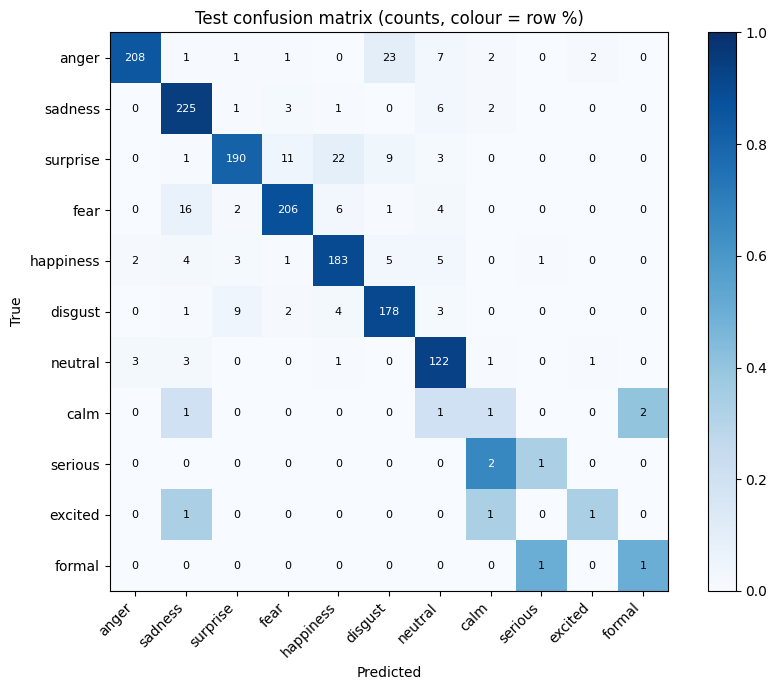


Accuracy per dataset:
                              acc    n
dataset                               
Indian_TTS_Emotion          0.385   13
Kannada_Emotional_Speech    0.578   45
MaSERC                      0.724   98
Malayalam Emotion Balanced  0.899  636
RapidOrc                    0.000    4
SUBESCO                     0.925  692
Telugu_Emotional_Speech     0.182   11

Accuracy per language:
             acc    n
language             
Bengali    0.925  692
Kannada    0.578   45
Malayalam  0.899  636
Marathi    0.724   98
Telugu     0.182   11
Unknown    0.294   17

Saved predictions to /content/gdrive_actual/MyDrive/DRDO_Emotion_Project/checkpoints/test_predictions_v3.csv


In [ ]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# ---- 1) Use the model currently in memory (epoch 8 of the v3 run) ----
print("Testing the model currently in memory (epoch 8 of the v3 run)")
# model.load_state_dict(torch.load(BEST_PATH, map_location=device))   # disabled on purpose
model.eval()

# ---- 2) Predict on the test set ----
ys, ps = [], []
with torch.no_grad():
    for b in test_loader:
        x, l = b["input_values"].to(device), b["lengths"]
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x, l)
        ps += logits.argmax(-1).cpu().tolist()
        ys += b["labels"].tolist()
ys, ps = np.array(ys), np.array(ps)

print(f"\nTEST accuracy : {accuracy_score(ys, ps):.4f}")
print(f"TEST macro-F1 (all 11 classes): {f1_score(ys, ps, average='macro', labels=list(range(NUM_LABELS)), zero_division=0):.4f}")
main7 = list(range(7))   # anger..neutral are ids 0-6
print(f"TEST macro-F1 (7 main emotions): {f1_score(ys, ps, average='macro', labels=main7, zero_division=0):.4f}\n")

# ---- 3) Per-class report ----
names = [id2label[i] for i in range(NUM_LABELS)]
print(classification_report(ys, ps, labels=list(range(NUM_LABELS)), target_names=names, zero_division=0, digits=3))

# ---- 4) Confusion matrix ----
cm = confusion_matrix(ys, ps, labels=list(range(NUM_LABELS)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_LABELS)); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(NUM_LABELS)); ax.set_yticklabels(names)
for i in range(NUM_LABELS):
    for j in range(NUM_LABELS):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Test confusion matrix (counts, colour = row %)")
plt.colorbar(im); plt.tight_layout(); plt.show()

# ---- 5) Accuracy per dataset and per language ----
res = test_df.reset_index(drop=True).copy()      # test_loader has shuffle=False, so order matches
res["pred"] = ps
res["correct"] = (res["y"].values == ps)
print("\nAccuracy per dataset:")
print(res.groupby("dataset")["correct"].agg(["mean", "count"]).rename(columns={"mean": "acc", "count": "n"}).round(3))
print("\nAccuracy per language:")
print(res.groupby("language")["correct"].agg(["mean", "count"]).rename(columns={"mean": "acc", "count": "n"}).round(3))

# ---- 6) Save results (separate file, so v2 results are not overwritten) ----
res.to_csv(f"{CKPT_DIR}/test_predictions_v3.csv", index=False)
print("\nSaved predictions to", f"{CKPT_DIR}/test_predictions_v3.csv")

###Backup test predictions

In [ ]:
import shutil, os
src = f"{CKPT_DIR}/test_predictions.csv"
if os.path.exists(src):
    shutil.copy(src, f"{CKPT_DIR}/test_predictions_v2.csv")
    print("Backed up to test_predictions_v2.csv")

Backed up to test_predictions_v2.csv
